# Signal AUC for 3 Binary Tasks

这个 notebook 用来做一个最小可复现检查：每个 word 有若干 numeric signal，以及 3 个二分类 task 标签；逐个计算 `signal -> task` 的 ROC AUC。

输入要求：一行一个 word；signal 列是数值；task 标签列是 `0/1`。如果暂时没有真实 CSV，下面会用一个很小的 demo 表跑通流程。

In [23]:
from pathlib import Path

import numpy as np
import pandas as pd

try:
    import matplotlib.pyplot as plt
    HAS_MATPLOTLIB = True
except ImportError:
    plt = None
    HAS_MATPLOTLIB = False

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

## 1. 配置输入、task 列、signal 列

 `ROOT_DIR` 。`SIGNAL_COLS = None` 需要输入不同model的表

In [24]:
# Cross-speaker pooled input. The notebook loads every speaker's *_with_signals.csv under this root.
ROOT_DIR = Path("/vol/tensusers/lgao/uncertainty_whisper/0_uncertainty_attribution_whisper/data/jasmin/output_final/v3_segment")
FILE_GLOB = "*/*_pr_mt_v3_task_label_table_with_signals.csv"

# Explicitly exclude skipped/link diagnostic files such as *_signal_link_skipped.csv.
EXCLUDE_NAME_CONTAINS = ["signal_link_skipped"]

# Local fallback for quick testing when /vol is not mounted on this machine.
FALLBACK_SINGLE_FILE = Path(r"C:\Users\lingy\Documents\uncertainty project\fn000117_pr_mt_v2_task_label_table_with_signals.csv")

# Three binary task label columns. Empty/None/NaN labels are excluded task-by-task.
TASK_COLS = ["task1", "task2", "task3"]

# 不参与 AUC 的标识列。
ID_COLS = ["segment_id", "word_idx", "asr_word"]

# AUC needs numeric score columns. aligned_alternative_words is a list/text column, so it is inspected but not used as a direct score.
SIGNAL_COLS = [
    "attn_entropy_mean",
    "A_ctc",
    "A_std",
    "audio_entropy",
    "decoding_consistency",
    "lm_confidence",
    "lm_entropy",
    "lm_margin",
]

OUTPUT_CSV = Path("cross_speaker_signal_task_auc_results.csv")

In [25]:
def read_table(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix in {".xlsx", ".xls"}:
        return pd.read_excel(path)
    if suffix == ".tsv":
        return pd.read_csv(path, sep="\t")
    return pd.read_csv(path)


def find_signal_files(root_dir: Path) -> list[Path]:
    if not root_dir.exists():
        return []
    files = sorted(root_dir.glob(FILE_GLOB))
    return [p for p in files if not any(token in p.name for token in EXCLUDE_NAME_CONTAINS)]


def load_signal_files(files: list[Path]) -> pd.DataFrame:
    frames = []
    for path in files:
        one = read_table(path)
        one.columns = [str(c).strip() for c in one.columns]
        one["source_file"] = str(path)
        one["speaker_from_path"] = path.parent.name
        frames.append(one)
    if not frames:
        raise FileNotFoundError(f"No matching signal files found under {ROOT_DIR}")
    return pd.concat(frames, ignore_index=True, sort=False)


signal_files = find_signal_files(ROOT_DIR)
if signal_files:
    df = load_signal_files(signal_files)
    print(f"Loaded {len(signal_files)} speaker files from {ROOT_DIR}")
    print(f"Pooled table: {df.shape[0]} rows x {df.shape[1]} columns")
elif FALLBACK_SINGLE_FILE.exists():
    df = load_signal_files([FALLBACK_SINGLE_FILE])
    print(f"ROOT_DIR not found or no files matched: {ROOT_DIR}")
    print(f"Using local fallback for testing: {FALLBACK_SINGLE_FILE}")
    print(f"Pooled table: {df.shape[0]} rows x {df.shape[1]} columns")
else:
    print(f"No files found under {ROOT_DIR}; fallback file also missing. Using a tiny demo table.")
    df = pd.DataFrame(
        {
            "segment_id": [0, 0, 0, 0, 1, 1, 1, 1],
            "word_idx": [0, 1, 2, 3, 0, 1, 2, 3],
            "asr_word": ["jeroen", "is", "onze", "buurman", "hello", "world", "again", "test"],
            "A_ctc": [0.529, 0.798, 0.210, 0.910, 0.330, 0.870, 0.420, 0.710],
            "A_std": [0.383, 0.102, 0.650, 0.080, 0.510, 0.120, 0.440, 0.220],
            "audio_entropy": [0.553, 0.609, 0.910, 0.320, 0.760, 0.410, 0.690, 0.470],
            "task1": [0, 0, 1, 0, 1, 0, 1, 0],
            "task2": [0, 1, 1, 0, 0, 1, 0, 1],
            "task3": [1, 1, 0, 0, 1, 0, 0, 1],
            "source_file": ["demo"] * 8,
            "speaker_from_path": ["demo"] * 8,
        }
    )

# 清理列名前后的空格，避免 " task 1 " 这种情况。
df.columns = [str(c).strip() for c in df.columns]
if signal_files:
    display(pd.DataFrame({"source_file": [str(p) for p in signal_files]}).head(20))
print("Number of pooled speakers:", df["speaker_from_path"].nunique() if "speaker_from_path" in df.columns else "unknown")
display(df.head())
display(pd.DataFrame({"column": df.columns, "dtype": [df[c].dtype for c in df.columns]}))

Loaded 71 speaker files from /vol/tensusers/lgao/uncertainty_whisper/0_uncertainty_attribution_whisper/data/jasmin/output_final/v3_segment
Pooled table: 58768 rows x 28 columns


,source_file
0,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
1,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
2,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
3,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
4,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
5,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
6,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
7,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
8,/vol/tensusers/lgao/uncertainty_whisper/0_unce...
9,/vol/tensusers/lgao/uncertainty_whisper/0_unce...


Number of pooled speakers: 71


,speaker,variant,asr_index,asr_word,mt_words,pr_mt_prompt_words,pr_v_prompt_words,mt_v_label,pr_mt_labels,pr_v_label,source_mt_v_json,source_pr_mt_json,source_pr_v_json,task1,task2,task3,attn_entropy_mean,A_ctc,A_std,audio_entropy,decoding_consistency,aligned_alternative_words,lm_confidence,lm_entropy,lm_margin,token_pieces,source_file,speaker_from_path
0,fn000049,v3,0,jeroen,jeroen,jeroen,jeroen,C,C,C,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,0,NaN,NaN,0.567487,0.529,0.382881,0.552843,0.2,"[""ja"", ""jaron"", ""ja"", ""ja""]",0.319005,2.405291,0.452383,"["" j"", ""ero"", ""en""]",/vol/tensusers/lgao/uncertainty_whisper/0_unce...,fn000049
1,fn000049,v3,1,is,is,is,is,C,C,C,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,0,NaN,NaN,0.540955,0.798,0.101500,0.608756,0.8,"[""is"", ""is"", ""is"", ""dus""]",0.868419,0.987724,0.830560,"["" is""]",/vol/tensusers/lgao/uncertainty_whisper/0_unce...,fn000049
2,fn000049,v3,2,onze,onze,onze,onze,C,C,C,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,0,NaN,NaN,0.532468,0.845,0.065728,0.527580,1.0,"[""onze"", ""onze"", ""onze"", ""onze""]",0.897770,0.735391,0.867526,"["" onze""]",/vol/tensusers/lgao/uncertainty_whisper/0_unce...,fn000049
3,fn000049,v3,3,buurman,buurman,buurman,buurman,C,C,C,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,0,NaN,NaN,0.557871,0.737,0.310155,0.402674,1.0,"[""buurman"", ""buurman"", ""buurman"", ""buurman""]",0.918788,0.597140,0.913238,"["" bu"", ""ur"", ""man""]",/vol/tensusers/lgao/uncertainty_whisper/0_unce...,fn000049
4,fn000049,v3,4,hij,hij,hij,hij,C,C,C,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,/vol/tensusers/lgao/uncertainty_whisper/0_unce...,0,NaN,NaN,0.564404,0.515,0.381211,0.618697,1.0,"[""hij"", ""hij"", ""hij"", ""hij""]",0.365763,2.491450,0.176008,"["" hij""]",/vol/tensusers/lgao/uncertainty_whisper/0_unce...,fn000049


,column,dtype
0,speaker,object
1,variant,object
2,asr_index,int64
3,asr_word,object
4,mt_words,object
5,pr_mt_prompt_words,object
6,pr_v_prompt_words,object
7,mt_v_label,object
8,pr_mt_labels,object
9,pr_v_label,object


## 2. 检查列并选择 signal

确认 3 个 task 是否存在，并把 task 转成 numeric `0/1`。如果某个 task 只有一个类别，AUC 会被跳过。

In [26]:
missing_tasks = [c for c in TASK_COLS if c not in df.columns]
if missing_tasks:
    raise ValueError(f"Missing task columns: {missing_tasks}. Available columns: {list(df.columns)}")

for col in TASK_COLS:
    df[col] = pd.to_numeric(df[col], errors="coerce")
    bad_values = sorted(set(df[col].dropna().unique()) - {0, 1})
    if bad_values:
        raise ValueError(f"Task column {col!r} has non-binary values: {bad_values[:10]}")

if SIGNAL_COLS is None:
    excluded = set(ID_COLS) | set(TASK_COLS)
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    signal_cols = [c for c in numeric_cols if c not in excluded]
else:
    signal_cols = list(SIGNAL_COLS)

missing_signals = [c for c in signal_cols if c not in df.columns]
if missing_signals:
    raise ValueError(f"Missing signal columns: {missing_signals}. Available columns: {list(df.columns)}")

for col in signal_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Task columns:", TASK_COLS)
print("Signal columns:", signal_cols)
print("Rows:", len(df))

label_summary = []
for task in TASK_COLS:
    valid = df[task].notna()
    label_summary.append(
        {
            "task": task,
            "n_total": len(df),
            "n_valid_used_for_auc": int(valid.sum()),
            "n_empty_or_none_excluded": int((~valid).sum()),
            "n_pos": int((df.loc[valid, task] == 1).sum()),
            "n_neg": int((df.loc[valid, task] == 0).sum()),
        }
    )
display(pd.DataFrame(label_summary))

Task columns: ['task1', 'task2', 'task3']
Signal columns: ['attn_entropy_mean', 'A_ctc', 'A_std', 'audio_entropy', 'decoding_consistency', 'lm_confidence', 'lm_entropy', 'lm_margin']
Rows: 58768


,task,n_total,n_valid_used_for_auc,n_empty_or_none_excluded,n_pos,n_neg
0,task1,58768,58768,0,9279,49489
1,task2,58768,3941,54827,804,3137
2,task3,58768,4784,53984,3090,1694


## 3. 计算 AUC

`auc` 的正类固定为 task 标签里的 `1`。如果 `auc < 0.5`，说明这个 signal 越小越倾向正类；`auc_best_direction = max(auc, 1 - auc)` 方便看区分强度。

In [27]:
def binary_auc(y_true, score):
    """ROC AUC for binary labels using average ranks; no sklearn required."""
    y = np.asarray(y_true, dtype=float)
    s = np.asarray(score, dtype=float)
    mask = np.isfinite(y) & np.isfinite(s)
    y = y[mask]
    s = s[mask]

    n_pos = int(np.sum(y == 1))
    n_neg = int(np.sum(y == 0))
    if n_pos == 0 or n_neg == 0:
        return np.nan, n_pos, n_neg, "only_one_class"
    if len(np.unique(s)) < 2:
        return np.nan, n_pos, n_neg, "constant_score"

    ranks = pd.Series(s).rank(method="average").to_numpy()
    rank_sum_pos = ranks[y == 1].sum()
    auc = (rank_sum_pos - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)
    return float(auc), n_pos, n_neg, "ok"


rows = []
for task in TASK_COLS:
    for signal in signal_cols:
        auc, n_pos, n_neg, status = binary_auc(df[task], df[signal])
        rows.append(
            {
                "task": task,
                "signal": signal,
                "auc": auc,
                "auc_best_direction": np.nan if pd.isna(auc) else max(auc, 1 - auc),
                "direction": None if pd.isna(auc) else ("higher_score_more_positive" if auc >= 0.5 else "lower_score_more_positive"),
                "n": int(df[[task, signal]].dropna().shape[0]),
                "n_pos": n_pos,
                "n_neg": n_neg,
                "status": status,
            }
        )

auc_df = pd.DataFrame(rows).sort_values(["task", "auc_best_direction"], ascending=[True, False])
display(auc_df)

auc_df.to_csv(OUTPUT_CSV, index=False)
print(f"Saved: {OUTPUT_CSV.resolve()}")

,task,signal,auc,auc_best_direction,direction,n,n_pos,n_neg,status
5,task1,lm_confidence,0.264604,0.735396,lower_score_more_positive,58768,9279,49489,ok
7,task1,lm_margin,0.265573,0.734427,lower_score_more_positive,58768,9279,49489,ok
6,task1,lm_entropy,0.723776,0.723776,higher_score_more_positive,58768,9279,49489,ok
4,task1,decoding_consistency,0.315168,0.684832,lower_score_more_positive,58768,9279,49489,ok
1,task1,A_ctc,0.405009,0.594991,lower_score_more_positive,58768,9279,49489,ok
3,task1,audio_entropy,0.563330,0.563330,higher_score_more_positive,58768,9279,49489,ok
2,task1,A_std,0.544865,0.544865,higher_score_more_positive,58768,9279,49489,ok
0,task1,attn_entropy_mean,0.542828,0.542828,higher_score_more_positive,58768,9279,49489,ok
12,task2,decoding_consistency,0.207730,0.792270,lower_score_more_positive,3941,804,3137,ok
9,task2,A_ctc,0.215687,0.784313,lower_score_more_positive,3941,804,3137,ok


Saved: /vol/tensusers/lgao/uncertainty_whisper/0_uncertainty_attribution_whisper/notebooks/cross_speaker_signal_task_auc_results.csv


## 4. 快速可视化

热图默认显示原始 AUC。接近 `0.5` 表示接近随机；接近 `1.0` 表示 signal 越高越能预测 label=1；接近 `0.0` 表示 signal 越低越能预测 label=1。

task,task1,task2,task3
signal,,,
attn_entropy_mean,0.542828,0.426644,0.491298
A_ctc,0.405009,0.215687,0.432468
A_std,0.544865,0.518303,0.546141
audio_entropy,0.563330,0.588559,0.521832
decoding_consistency,0.315168,0.207730,0.353456
lm_confidence,0.264604,0.531654,0.359902
lm_entropy,0.723776,0.460291,0.618563
lm_margin,0.265573,0.534678,0.357236


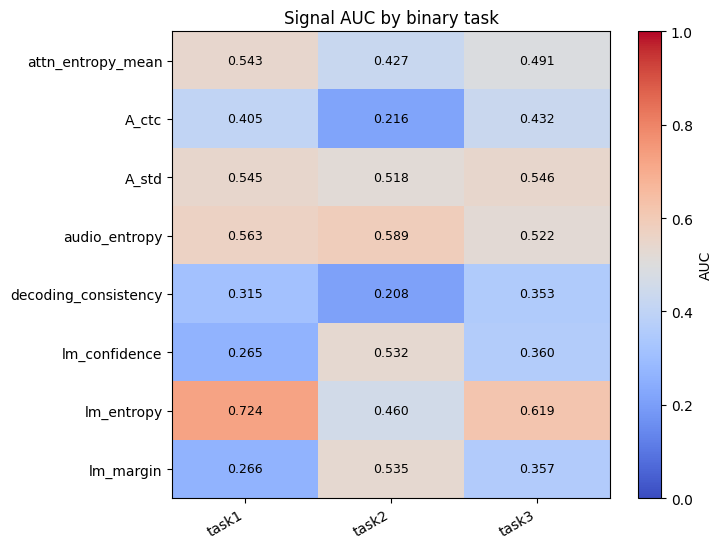

In [28]:
pivot = auc_df.pivot(index="signal", columns="task", values="auc").reindex(signal_cols)
display(pivot)

if not HAS_MATPLOTLIB:
    print("matplotlib is not installed in this kernel; showing the AUC pivot table only.")
else:
    fig, ax = plt.subplots(figsize=(1.8 * len(TASK_COLS) + 2, 0.45 * max(len(signal_cols), 4) + 2))
    im = ax.imshow(pivot.to_numpy(dtype=float), vmin=0, vmax=1, cmap="coolwarm", aspect="auto")

    ax.set_xticks(np.arange(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
    ax.set_yticks(np.arange(len(pivot.index)))
    ax.set_yticklabels(pivot.index)
    ax.set_title("Signal AUC by binary task")

    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            value = pivot.iloc[i, j]
            label = "NA" if pd.isna(value) else f"{value:.3f}"
            ax.text(j, i, label, ha="center", va="center", color="black", fontsize=9)

    fig.colorbar(im, ax=ax, label="AUC")
    plt.tight_layout()
    plt.show()

## 5. 每个 task 的最佳 signal

这里按 `auc_best_direction` 排序，所以同时能看到正向强预测和反向强预测。

In [29]:
best_by_task = (
    auc_df[auc_df["status"].eq("ok")]
    .sort_values(["task", "auc_best_direction"], ascending=[True, False])
    .groupby("task", as_index=False)
    .head(5)
)
display(best_by_task)

,task,signal,auc,auc_best_direction,direction,n,n_pos,n_neg,status
5,task1,lm_confidence,0.264604,0.735396,lower_score_more_positive,58768,9279,49489,ok
7,task1,lm_margin,0.265573,0.734427,lower_score_more_positive,58768,9279,49489,ok
6,task1,lm_entropy,0.723776,0.723776,higher_score_more_positive,58768,9279,49489,ok
4,task1,decoding_consistency,0.315168,0.684832,lower_score_more_positive,58768,9279,49489,ok
1,task1,A_ctc,0.405009,0.594991,lower_score_more_positive,58768,9279,49489,ok
12,task2,decoding_consistency,0.207730,0.792270,lower_score_more_positive,3941,804,3137,ok
9,task2,A_ctc,0.215687,0.784313,lower_score_more_positive,3941,804,3137,ok
11,task2,audio_entropy,0.588559,0.588559,higher_score_more_positive,3941,804,3137,ok
8,task2,attn_entropy_mean,0.426644,0.573356,lower_score_more_positive,3941,804,3137,ok
14,task2,lm_entropy,0.460291,0.539709,lower_score_more_positive,3941,804,3137,ok
